# 03 · Analysis

Reads `results/` only — no training here.
1. Overview of all systems (box plots)
2. Bayesian comparisons with a ROPE: is A better, equivalent, or worse than B?
3. Pick the best model, look at its errors

In [1]:
# Setup: make the course code (part1) and our code (src) importable.
# Run notebooks from this folder (JupyterLab / VS Code do this by default).
import sys
from pathlib import Path

REPO_ROOT = Path.cwd().resolve().parents[1]
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

%load_ext autoreload
%autoreload 2

In [2]:
from part1 import analysis
from src import config, results_io

## Overview

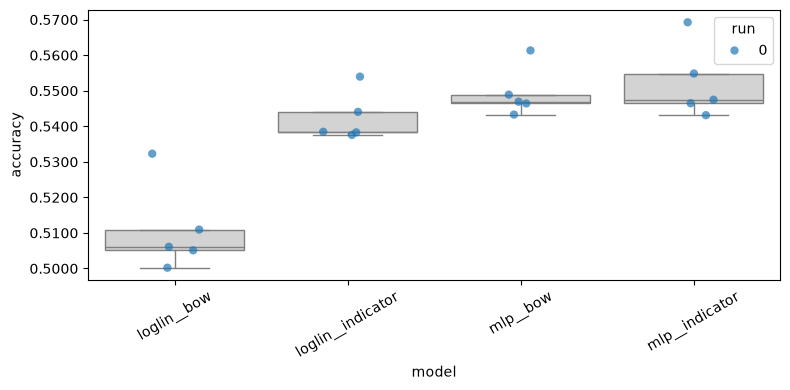

In [3]:
scores = results_io.fold_scores()
df = analysis.make_data_frame(results_io.for_dataframe())
analysis.plot_box_and_points(df, metric="accuracy")

## Bayesian comparison with ROPE

ROPE = the smallest difference we would care about in practice.
**Our choice:** ___ because ___.

((np.float64(0.00015676339106259922),
  np.float64(0.0010501571543149865),
  np.float64(0.9987930794546224)),
 (<Figure size 640x480 with 1 Axes>,
  <Axes: title={'center': 'A=loglin__bow vs. B=mlp__bow'}, xlabel='Mean difference: $\\mu$'>))

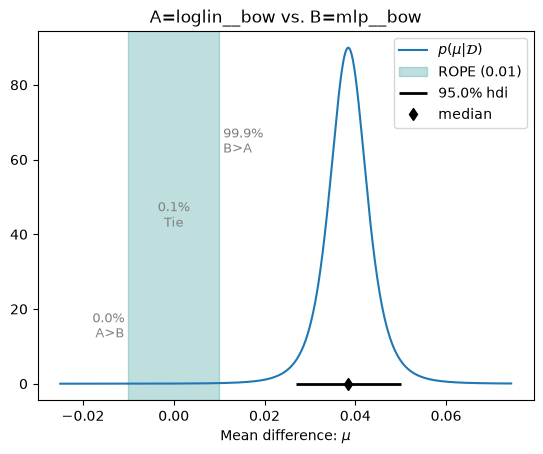

In [4]:
ROPE = 0.01  # TODO: motivate

a, b = "loglin__bow", "mlp__bow"   # pick pairs to compare
test = analysis.BenavoliCorrelatedT(scores[a], scores[b], names=[a, b])
test.probs(ROPE), test.plot(ROPE)

## Best model and error analysis

- 